# Fase 4 — Inteligencia Artificial Explicable con SHAP

Este notebook audita el modelo campeón de la Fase 3 (**CatBoost**) mediante `shap.TreeExplainer`. Se conserva exactamente la partición agrupada por conglomerado y se explican únicamente los 1,924 registros del conjunto de prueba.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import config
from src.explainability import ejecutar_fase4

pd.set_option('display.max_colwidth', 80)
print(f'Proyecto: {ROOT}')

C:\Users\Jalea\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Proyecto: C:\Users\Jalea\Documents\U\C8\inteligencia_artificial\u2_ex\proyecto_ia


## 1. Cálculo de explicaciones

Los valores SHAP se calculan sobre la salida cruda de XGBoost (log-odds). Un valor positivo incrementa el riesgo estimado de rezago y uno negativo lo reduce. Los ejes de las variables numéricas se presentan en su escala original para facilitar la interpretación.

In [2]:
df = pd.read_parquet(config.DATASET_FINAL_PARQUET)
resultados = ejecutar_fase4(df)
print('Explicaciones calculadas:', resultados['metadata']['n_test_explicado'])

{
  "modelo_explicado": "CatBoostClassifier",
  "metodo": "shap.TreeExplainer",
  "escala_shap": "log-odds (salida cruda del clasificador)",
  "n_test_explicado": 1924,
  "n_variables_transformadas": 46,
  "top_15": [
    {
      "ranking": 1,
      "variable": "dominio_25_6.0",
      "shap_abs_medio": 0.19619287789055667
    },
    {
      "ranking": 2,
      "variable": "escale_total_locales",
      "shap_abs_medio": 0.17846468496737222
    },
    {
      "ranking": 3,
      "variable": "p1143_25",
      "shap_abs_medio": 0.17168327116940146
    },
    {
      "ranking": 4,
      "variable": "escale_ratio_alumno_docente",
      "shap_abs_medio": 0.16528962806081107
    },
    {
      "ranking": 5,
      "variable": "log_gasto_pc",
      "shap_abs_medio": 0.14830762824313998
    },
    {
      "ranking": 6,
      "variable": "log_ingreso_pc",
      "shap_abs_medio": 0.12592218159054977
    },
    {
      "ranking": 7,
      "variable": "dominio_25_7.0",
      "shap_abs_medio": 0.12372

Explicaciones calculadas: 1924


## 2. Importancia global y SHAP Summary (Beeswarm)

,ranking,variable,shap_abs_medio
0,1,dominio_25_6.0,0.196193
1,2,escale_total_locales,0.178465
2,3,p1143_25,0.171683
3,4,escale_ratio_alumno_docente,0.165290
4,5,log_gasto_pc,0.148308
5,6,log_ingreso_pc,0.125922
6,7,dominio_25_7.0,0.123725
7,8,escale_pct_colegios_publicos,0.122194
8,9,escale_pct_locales_rurales,0.099477
9,10,p207_25_2.0,0.098349


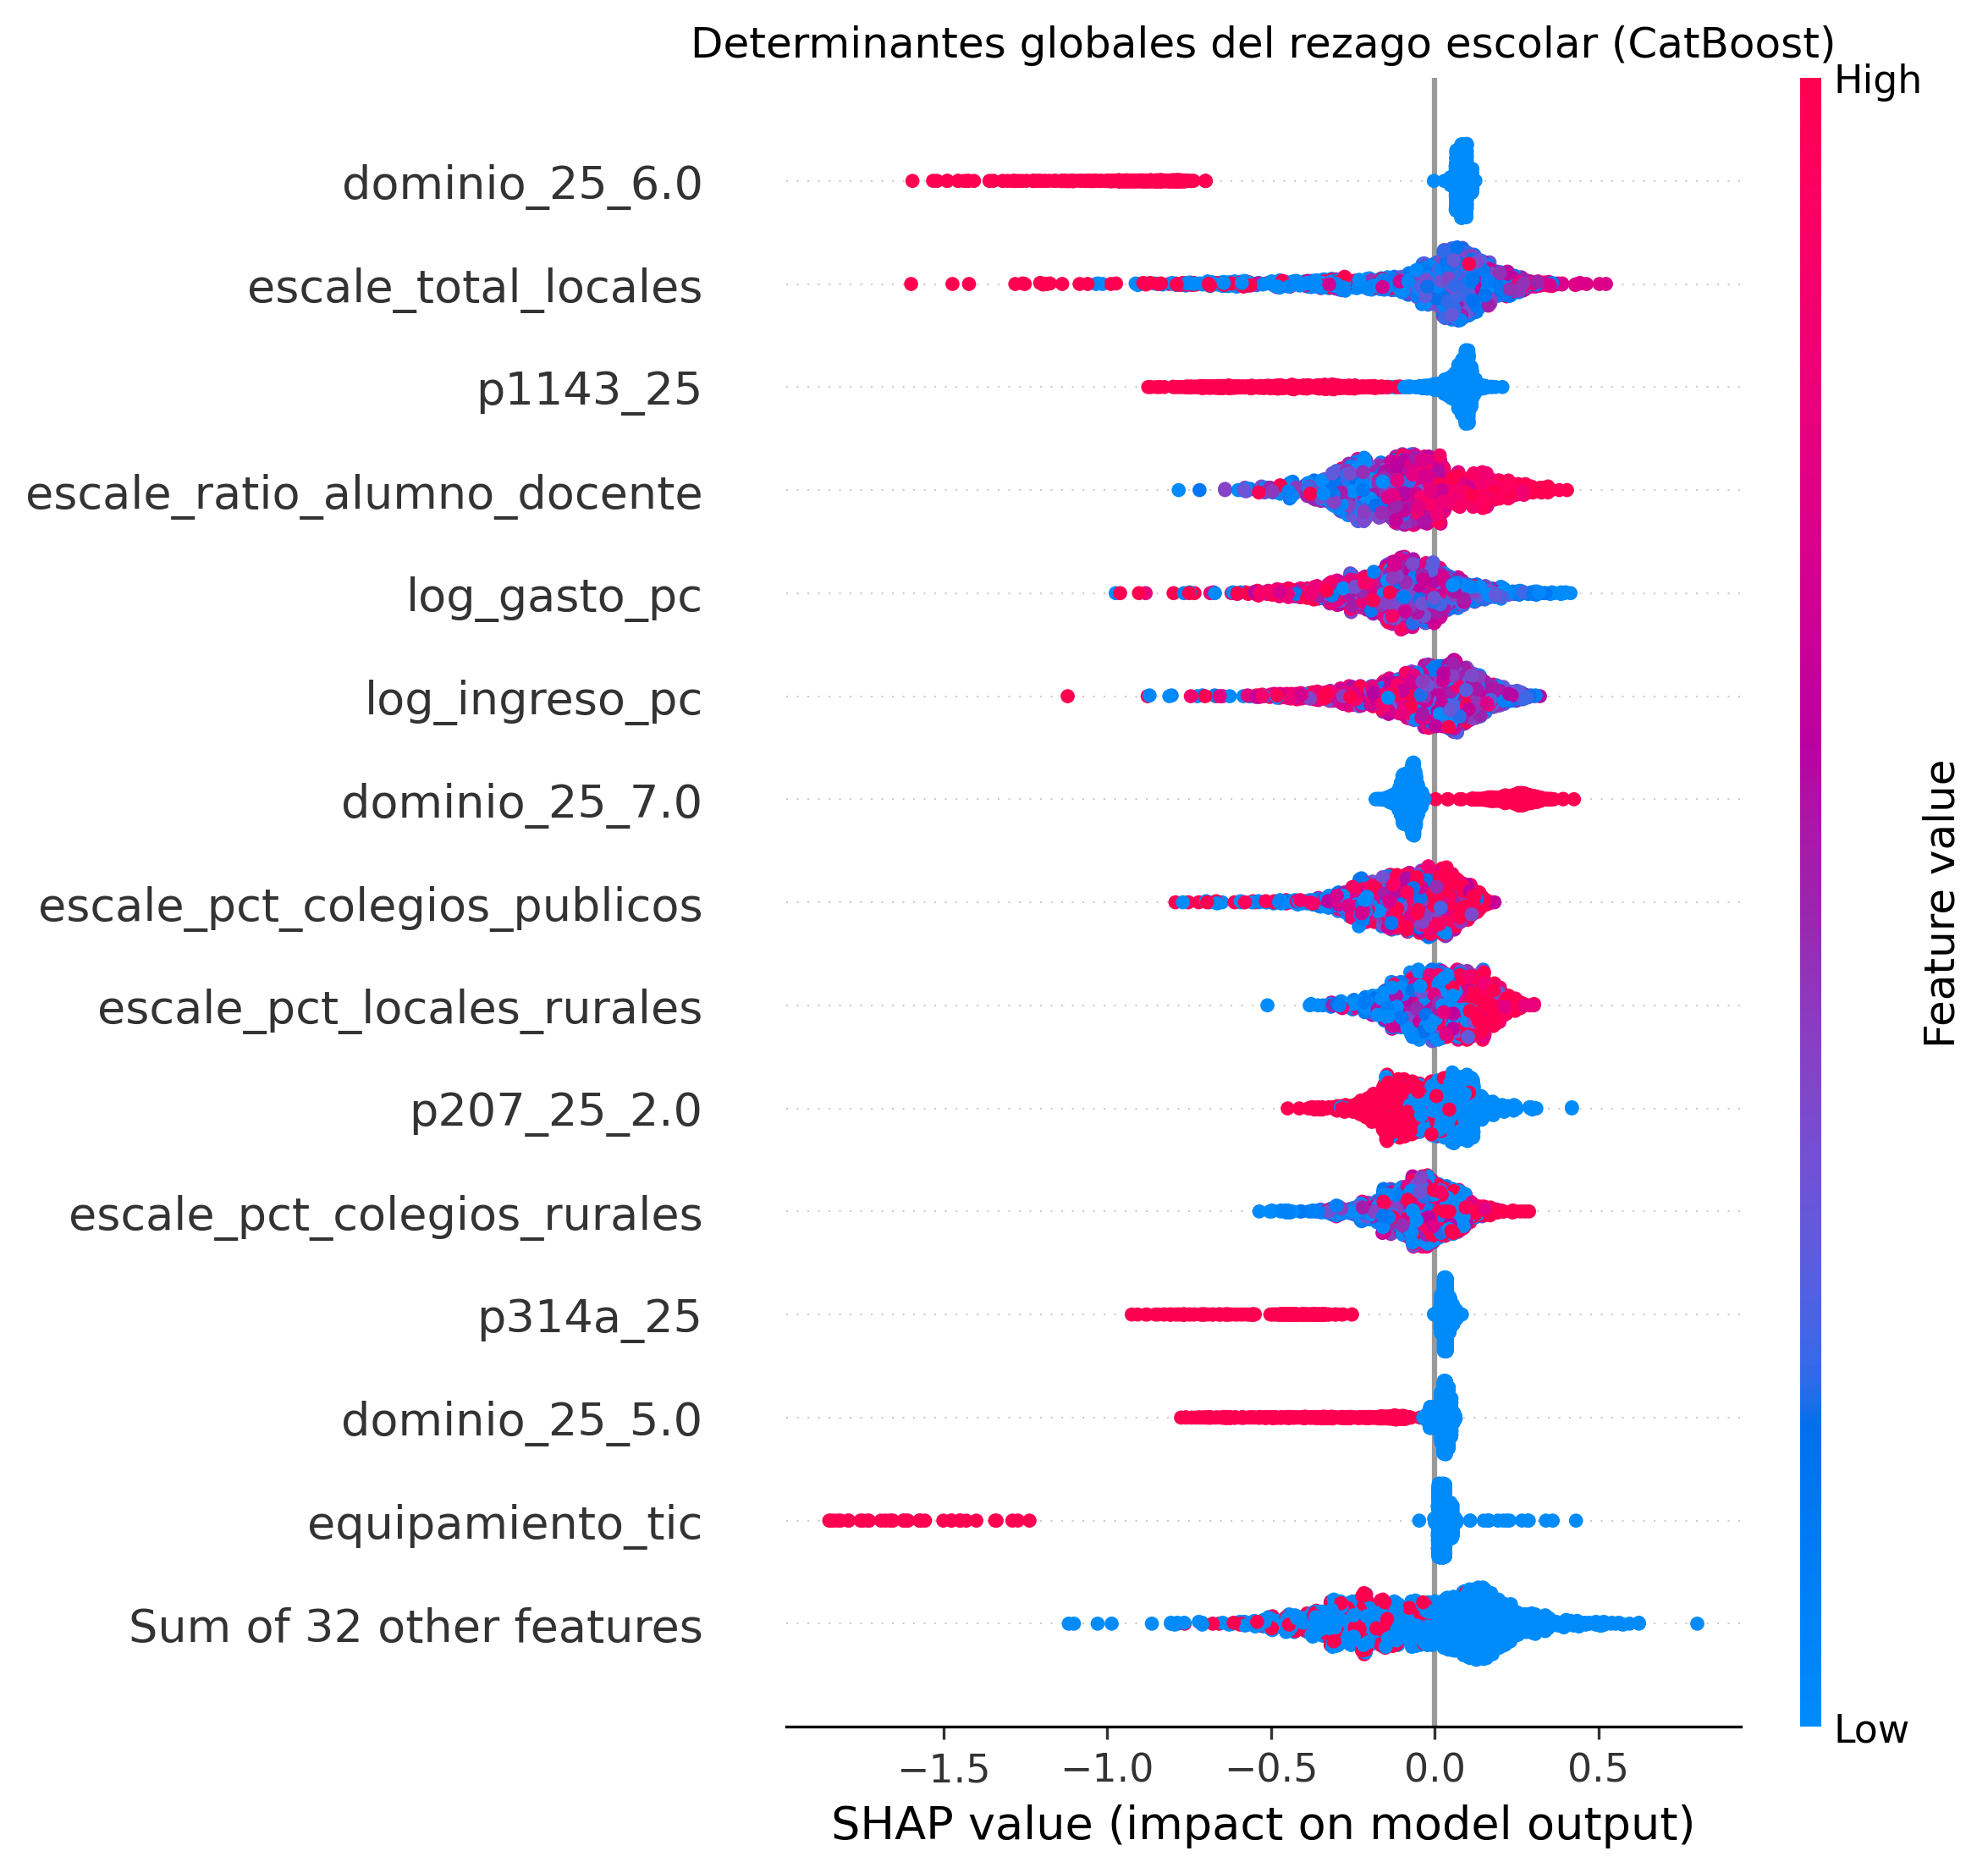

In [3]:
display(resultados['importance'].head(15))
display(Image(filename=str(config.FIGURES_DIR / 'shap_summary_beeswarm.png'), width=900))

El dominio geográfico, la oferta de locales escolares, la disponibilidad de tableta, el ratio alumno/docente y los recursos económicos concentran la mayor importancia global. En general, mejores recursos del hogar reducen la salida del modelo. Las variables SHAP representan asociaciones aprendidas por el modelo y no deben interpretarse como efectos causales.

## 3. Dependencias e interacciones no lineales

Se analizan las dos interacciones definidas en el plan: lengua originaria–internet y gasto familiar–ratio alumno/docente.

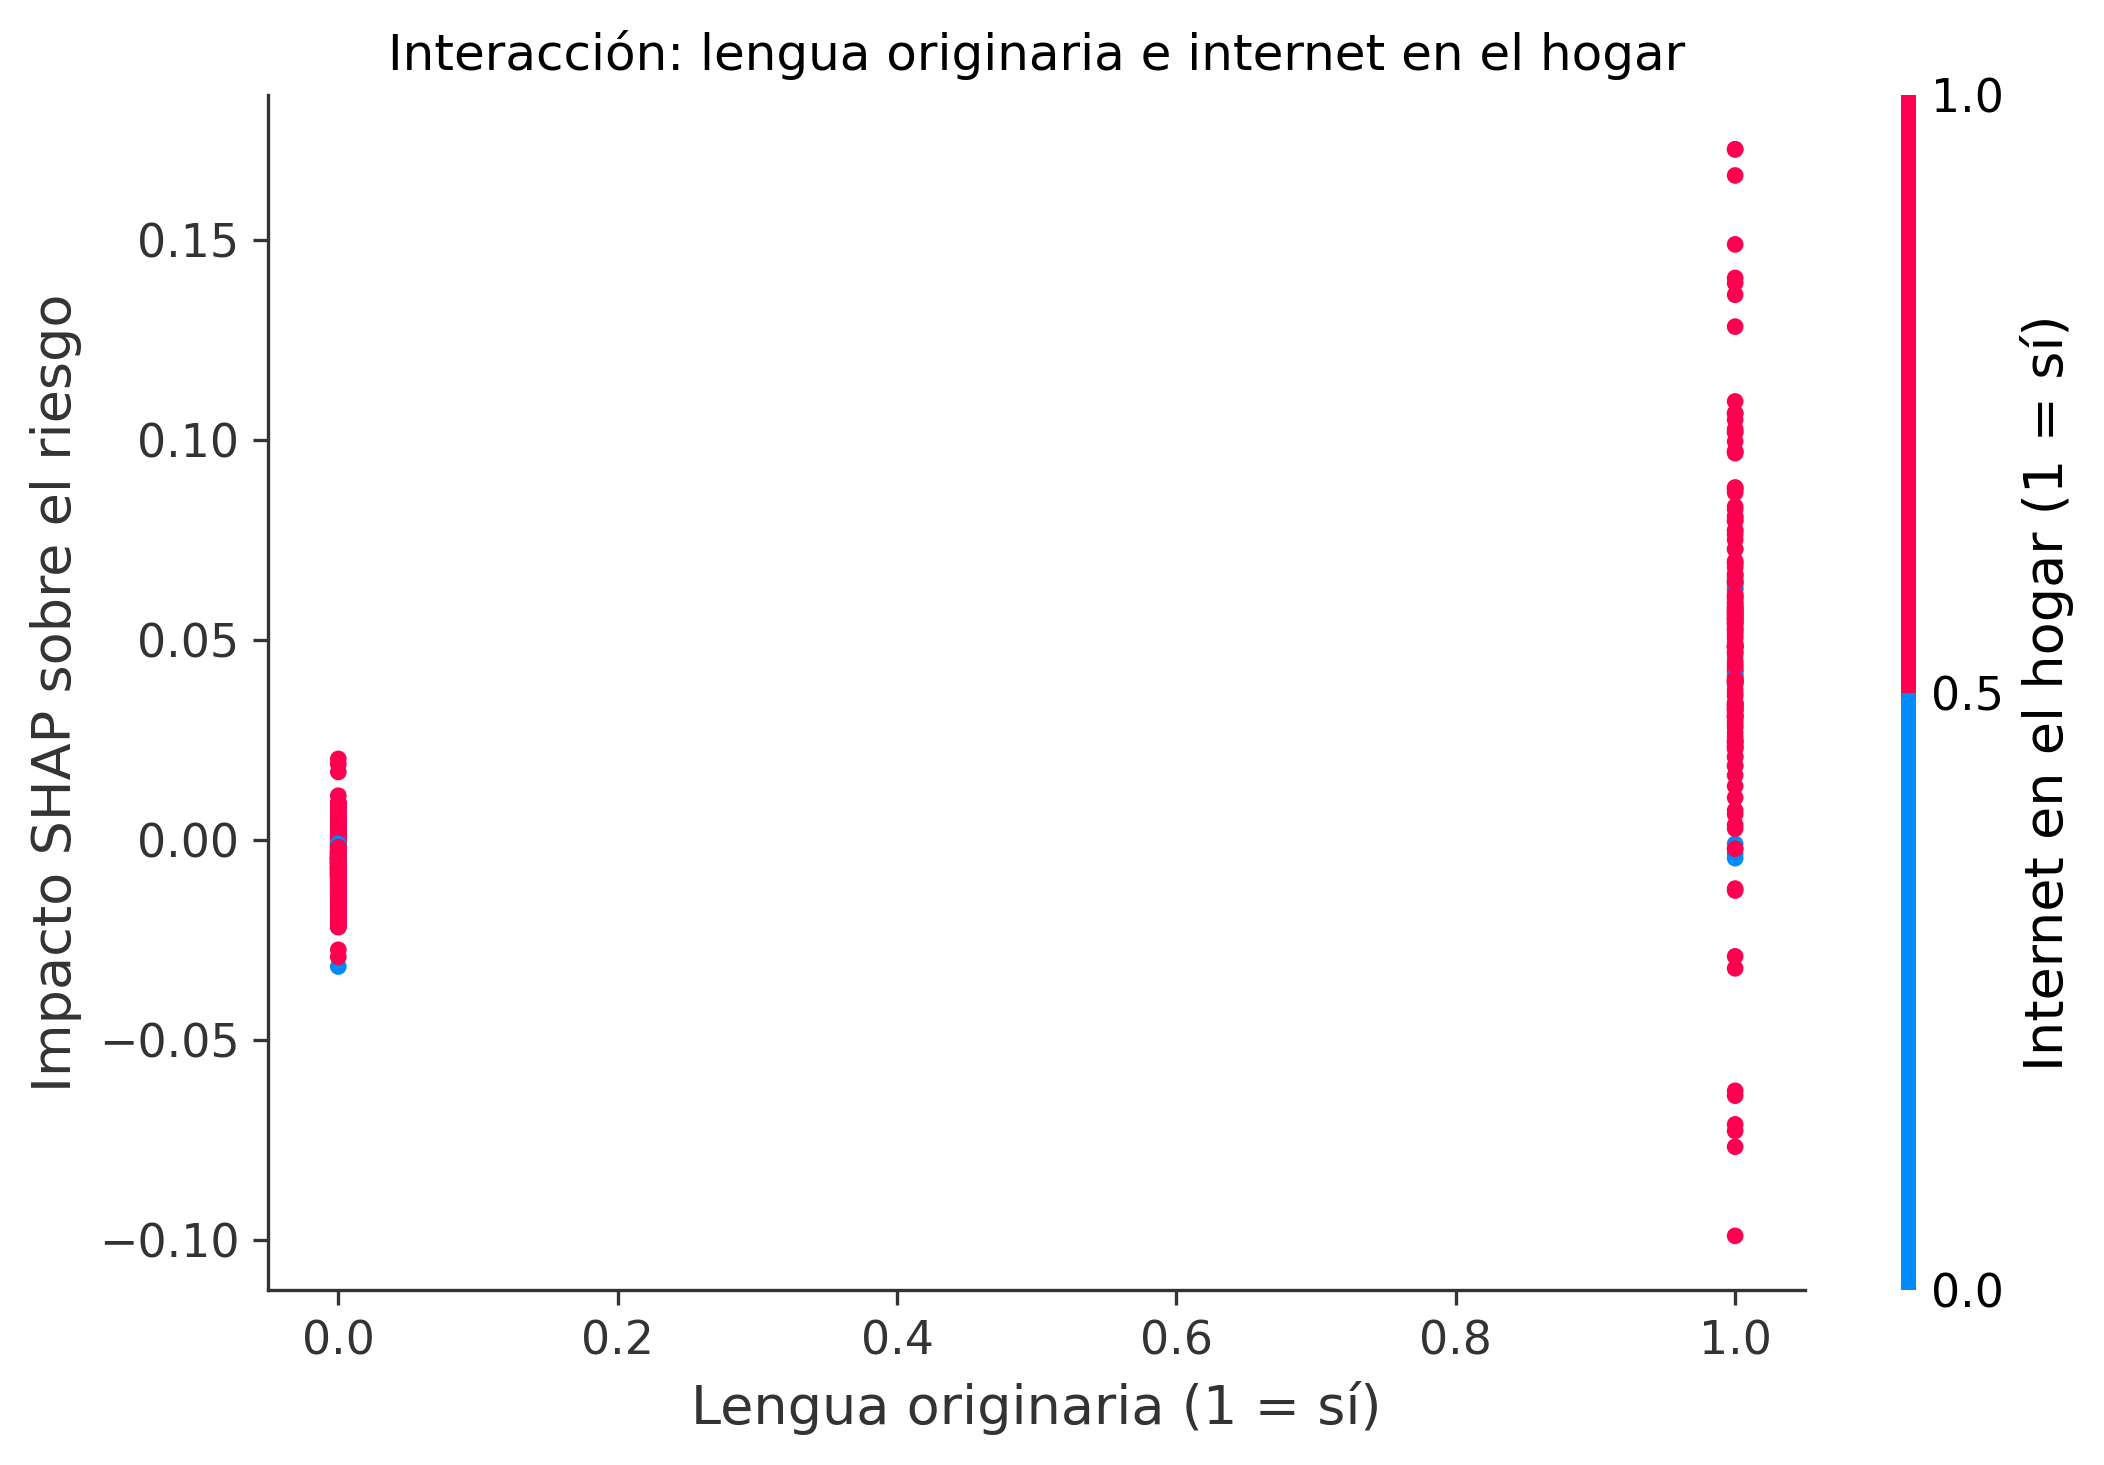

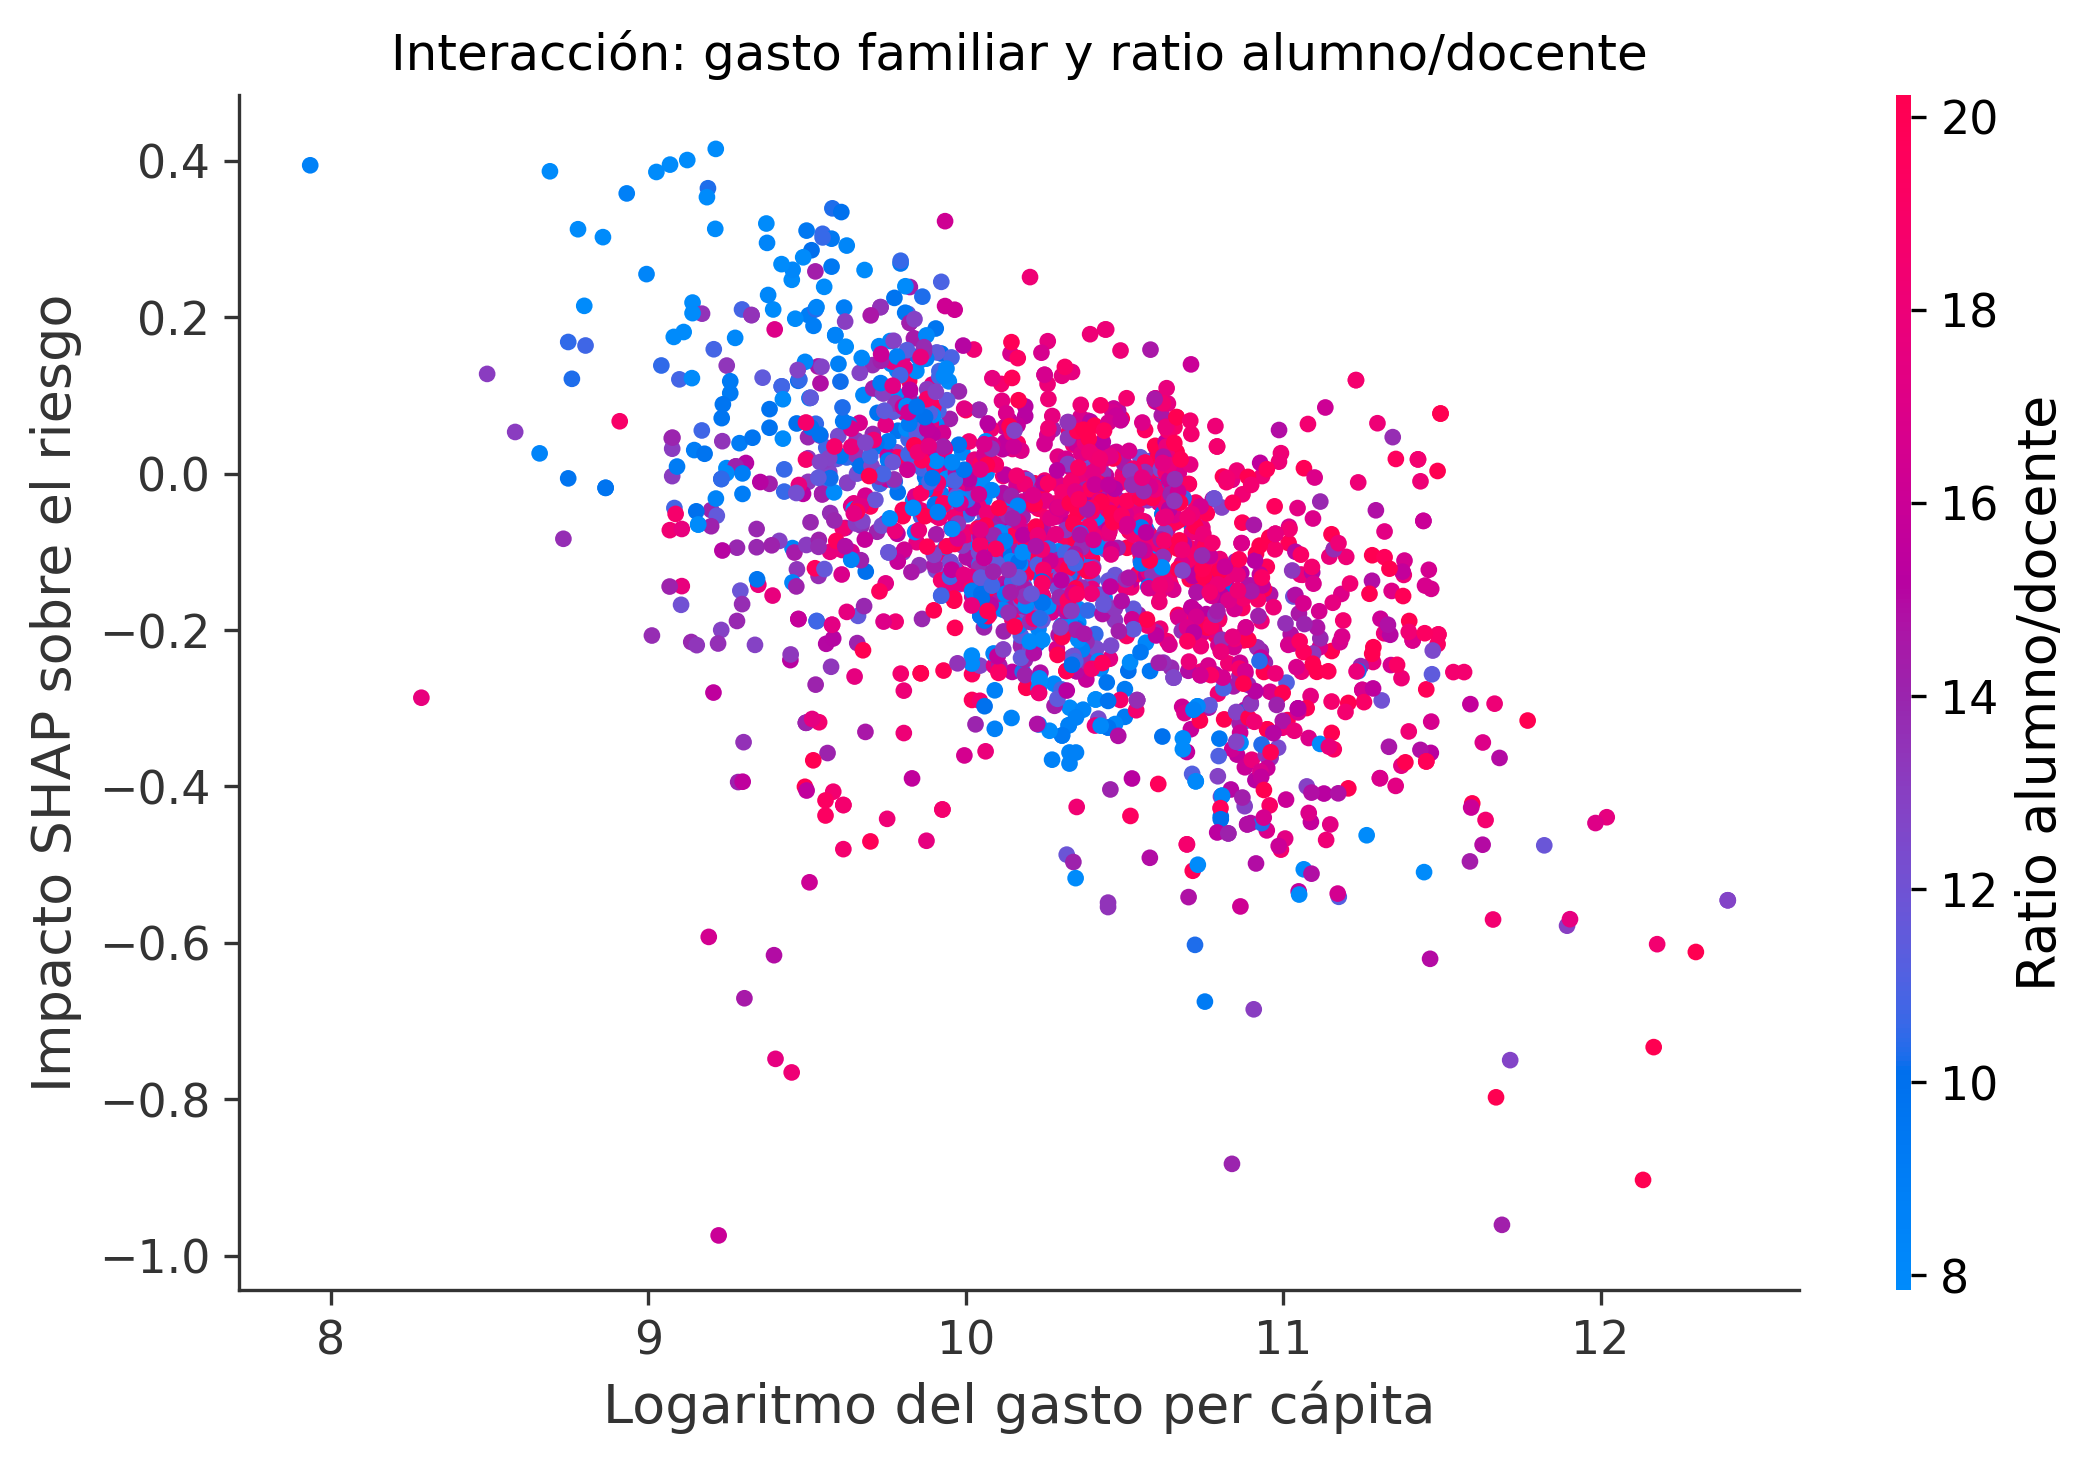

In [4]:
display(Image(filename=str(config.FIGURES_DIR / 'shap_dependencia_lengua_internet.png'), width=850))
display(Image(filename=str(config.FIGURES_DIR / 'shap_dependencia_gasto_ratio.png'), width=850))

La lengua originaria muestra un efecto positivo pequeño sobre el riesgo estimado; la separación cromática por internet es limitada, por lo que estos datos **no respaldan un efecto multiplicador fuerte** entre ambas variables. En contraste, la relación gasto–riesgo es claramente no lineal: el riesgo desciende al aumentar el gasto y el patrón varía según la carga alumno/docente.

## 4. Auditoría individual: casos extremos correctamente clasificados

,caso,posicion_test,indice_original,conglome_25,rezago_real,probabilidad_modelo,prediccion_umbral_05
0,alto_riesgo,1795,22242,020232,1,0.827696,1
1,bajo_riesgo,912,10199,016249,0,0.006263,0


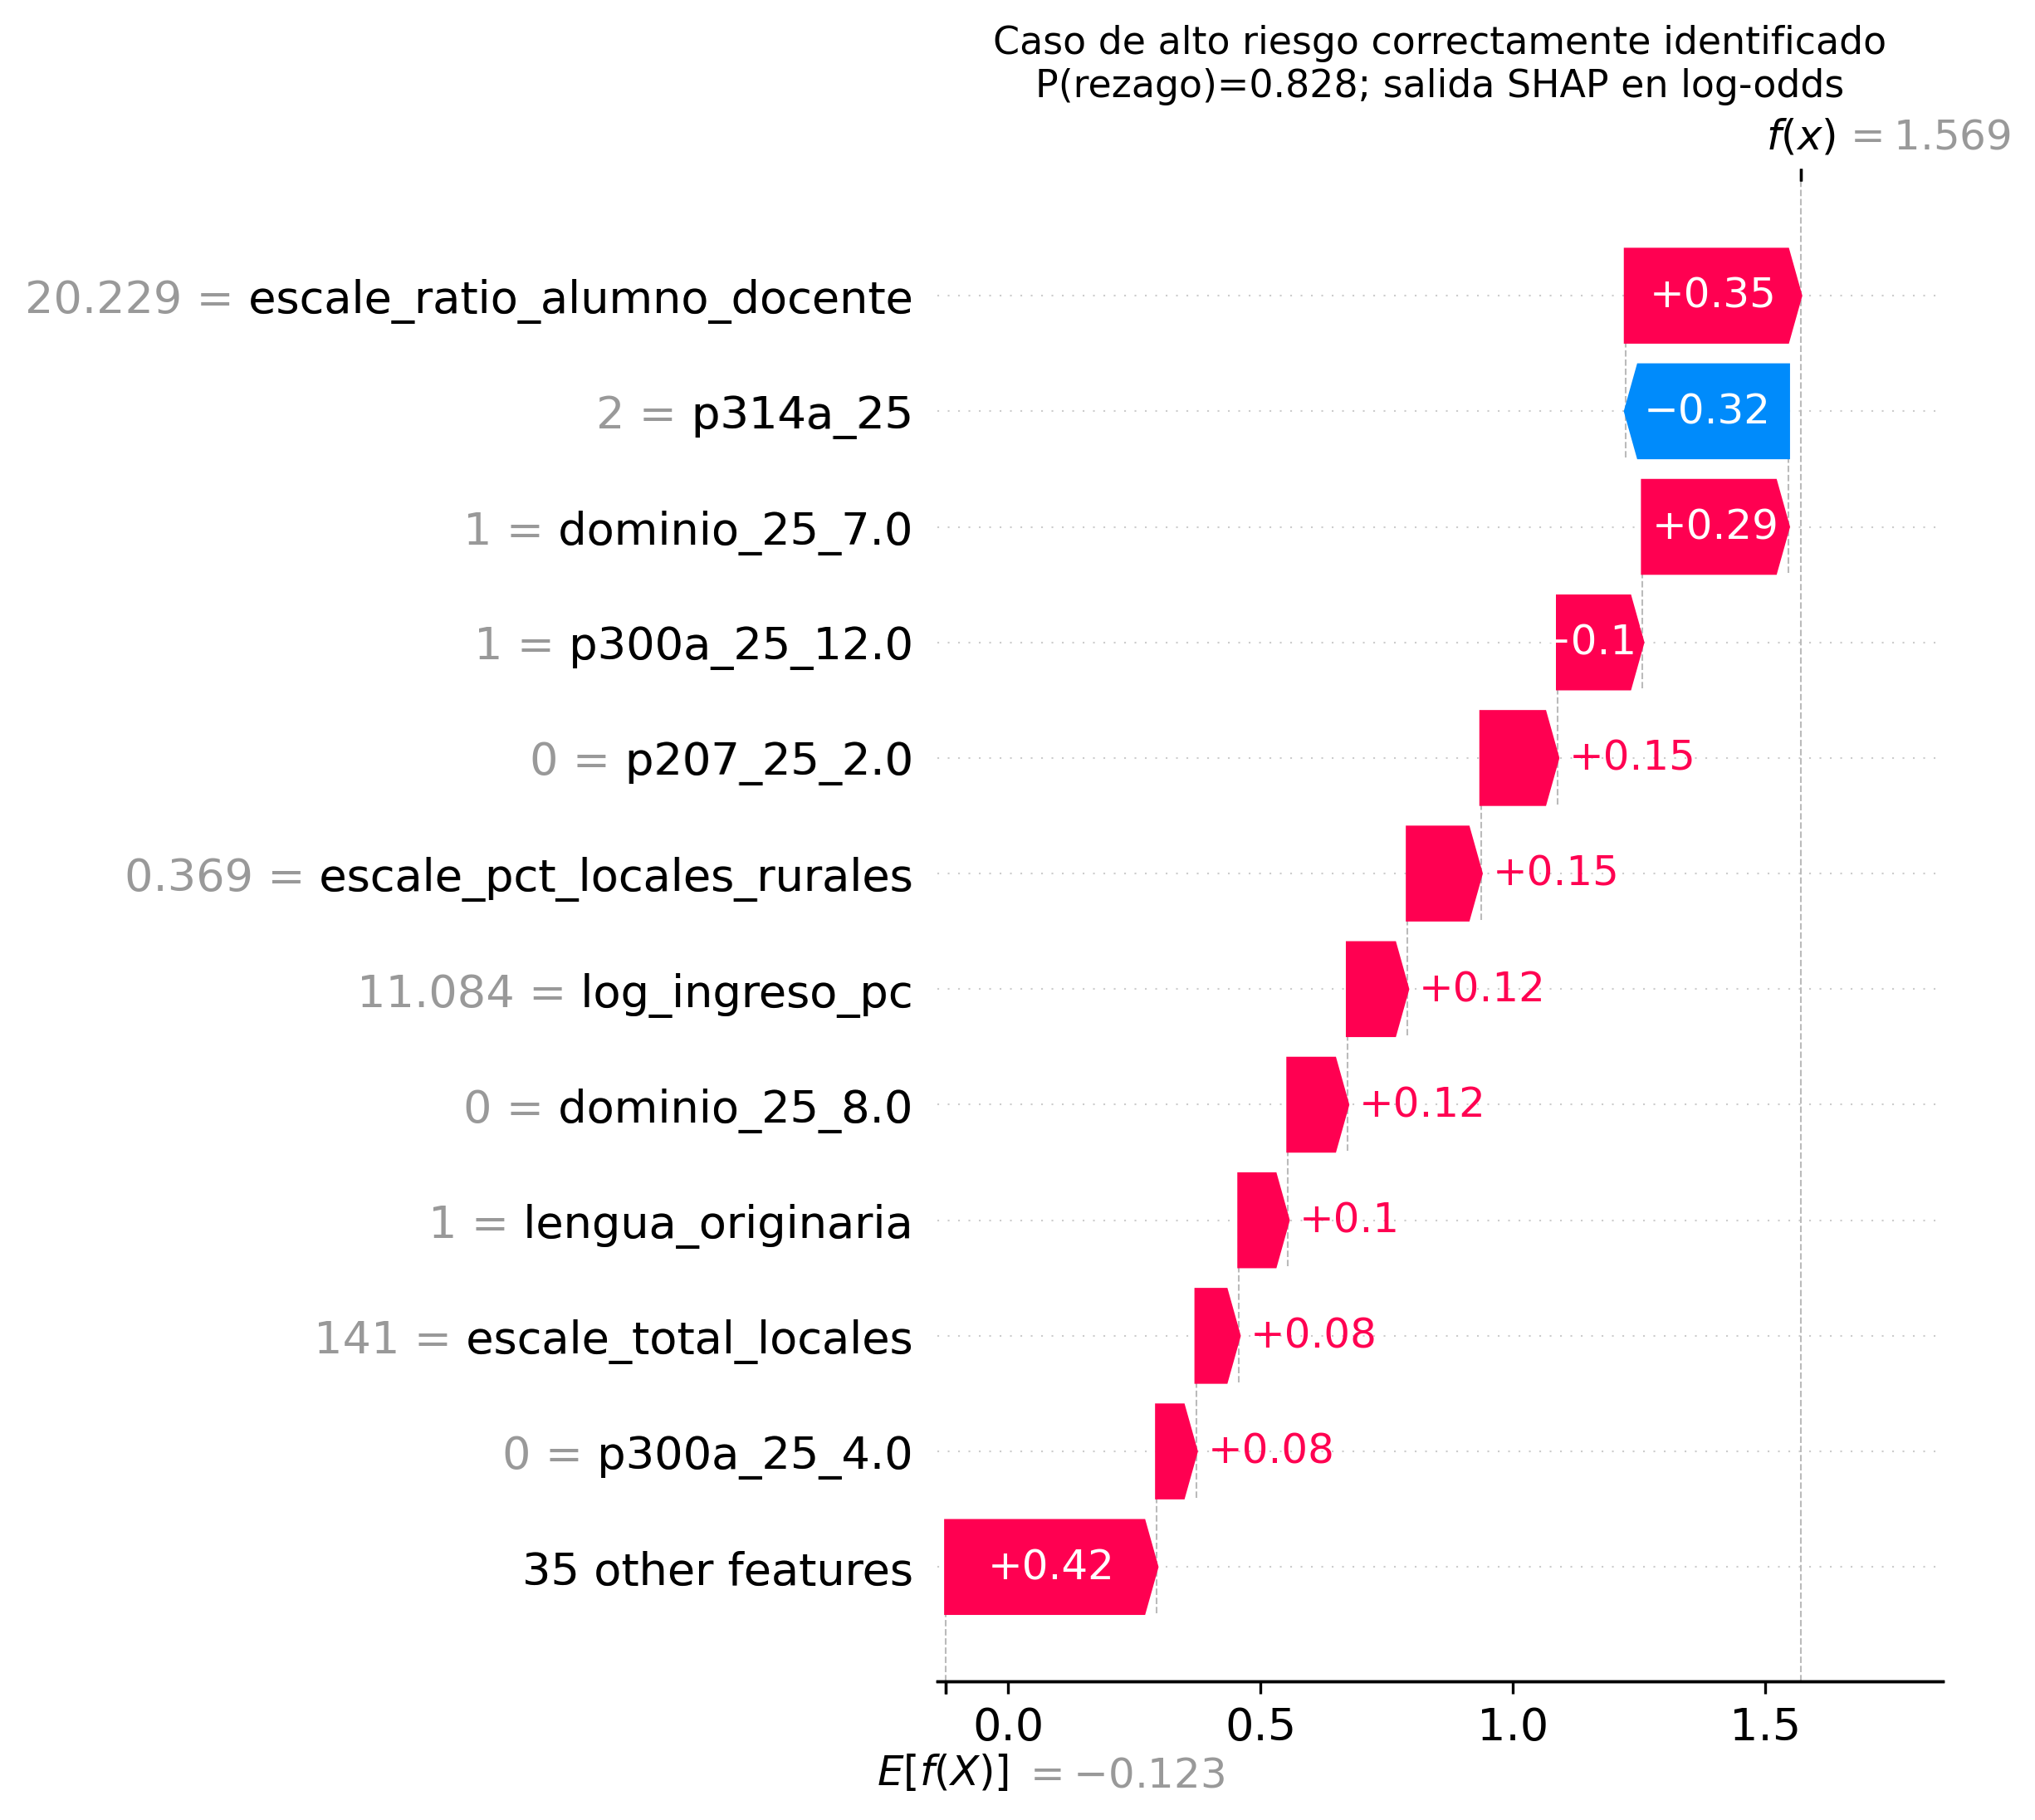

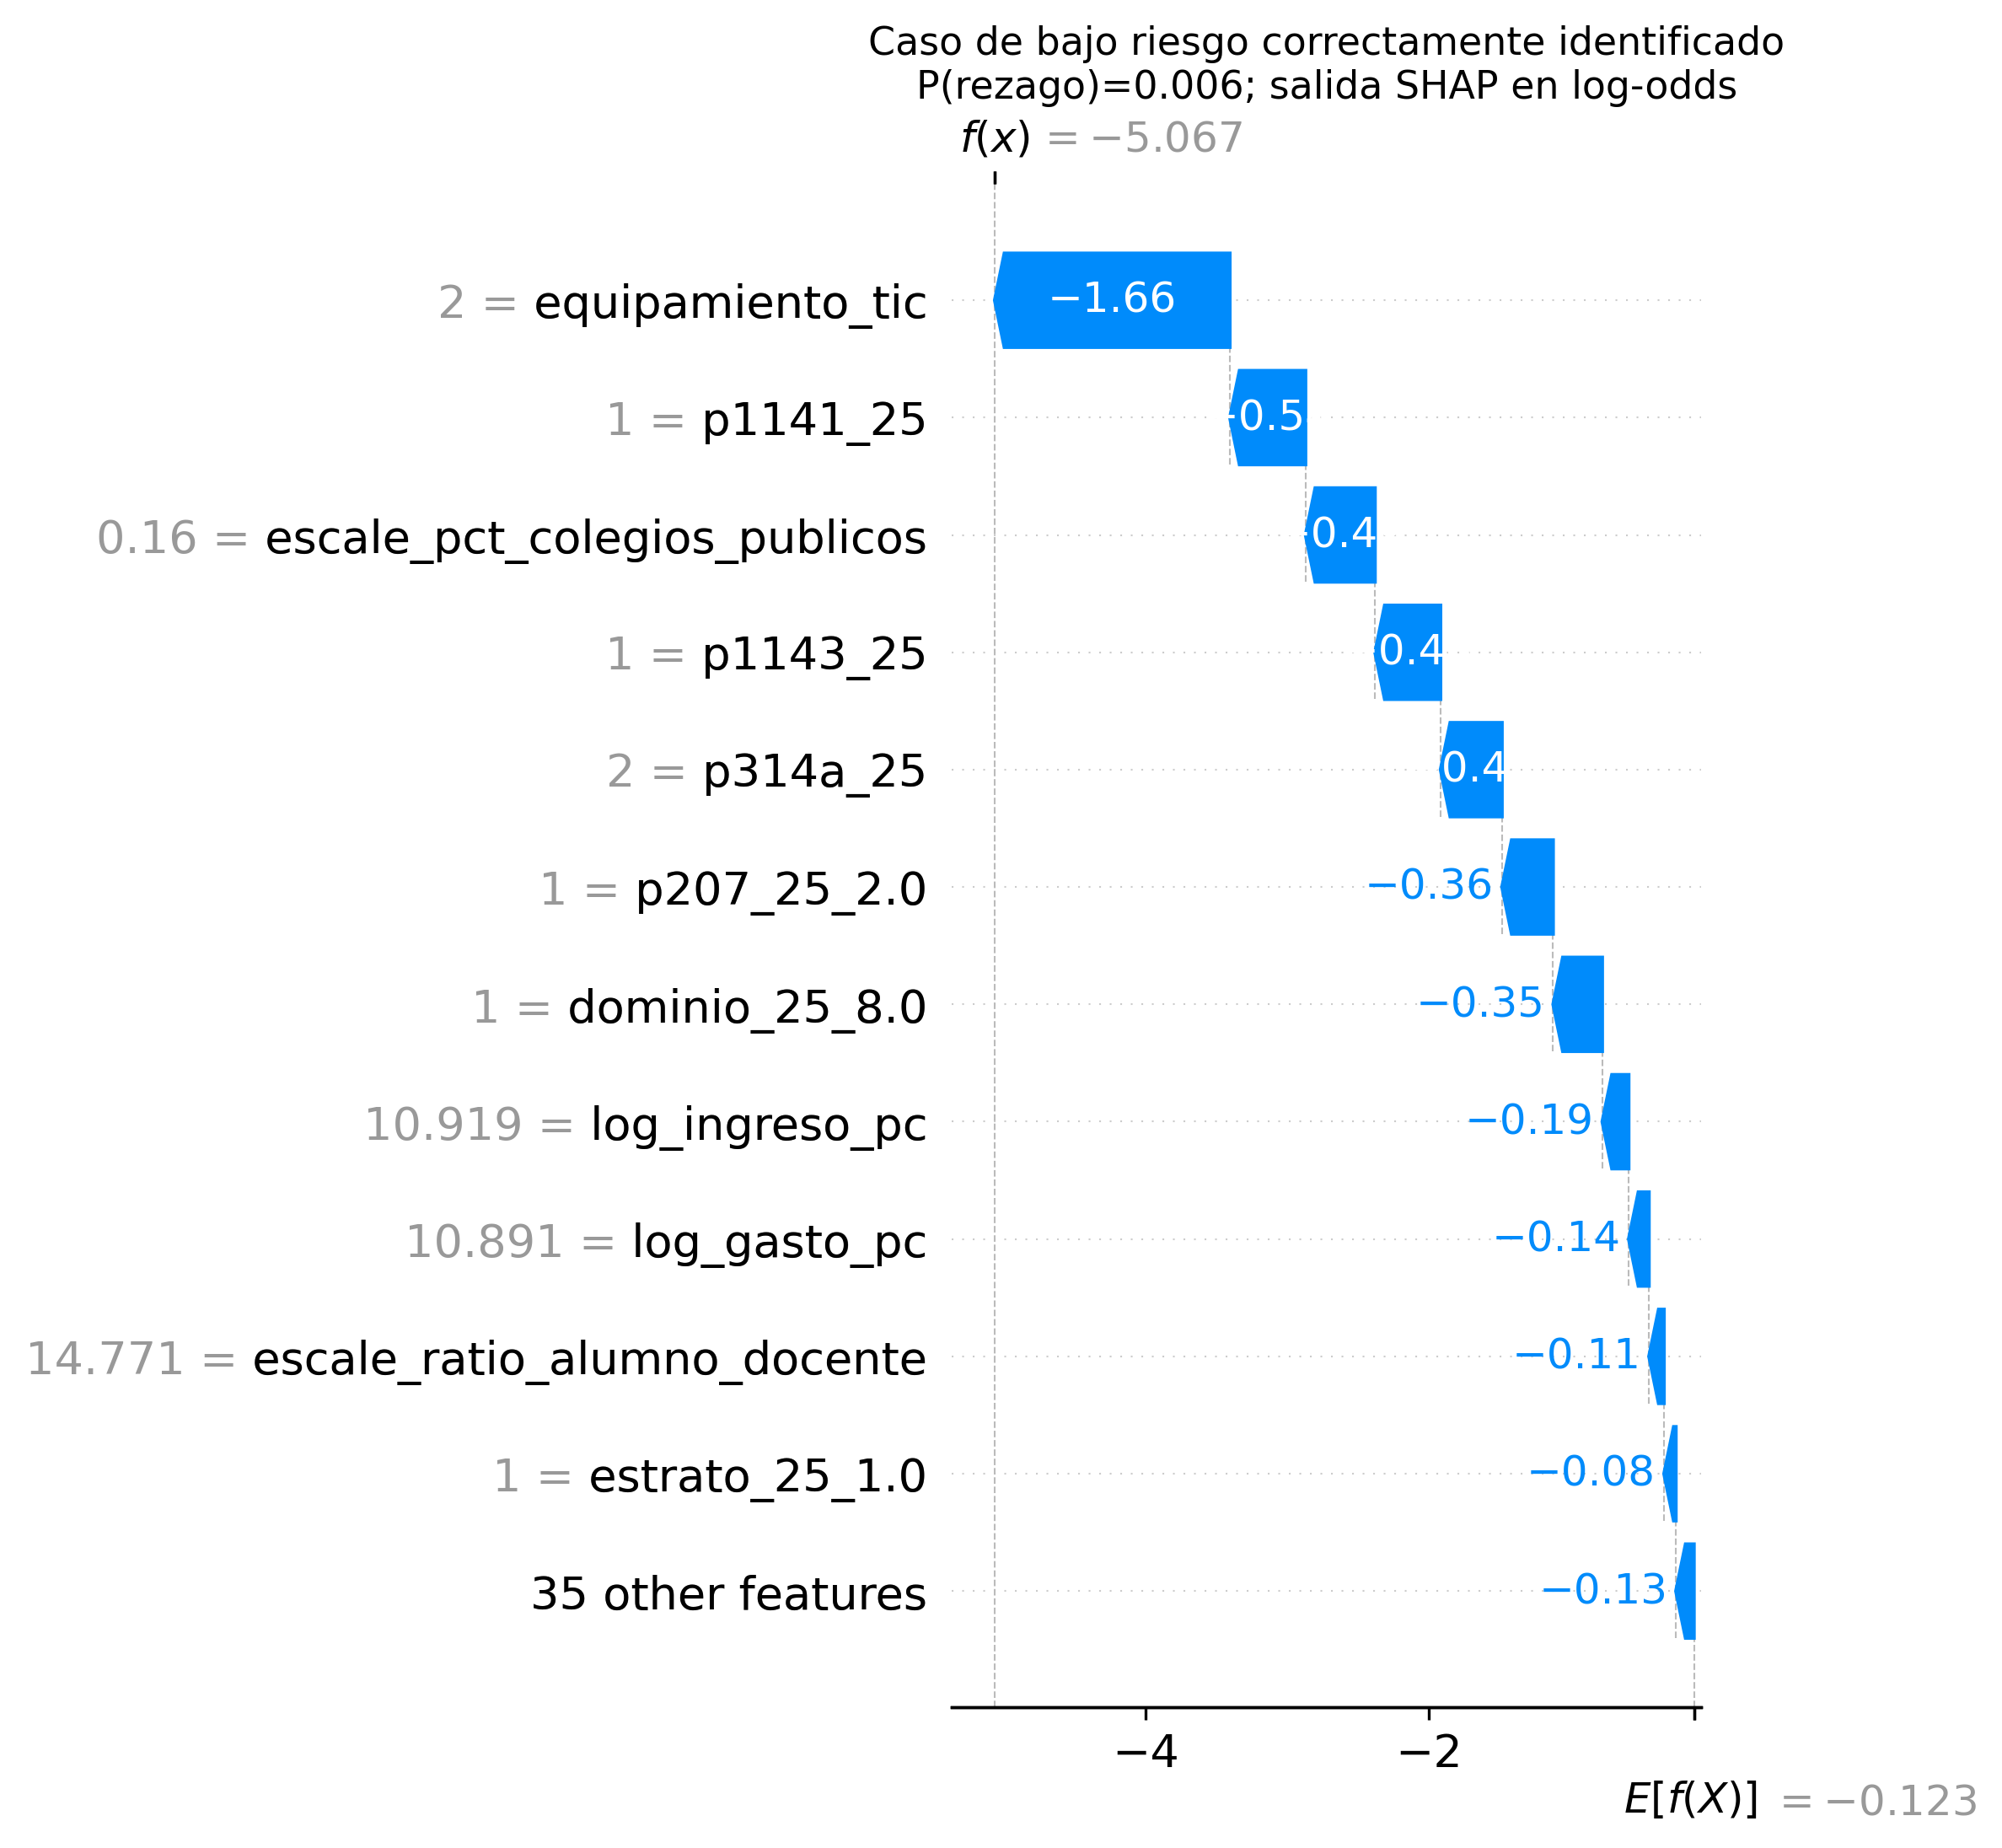

In [5]:
display(resultados['cases'])
display(Image(filename=str(config.FIGURES_DIR / 'shap_waterfall_alto_riesgo.png'), width=850))
display(Image(filename=str(config.FIGURES_DIR / 'shap_waterfall_bajo_riesgo.png'), width=850))

## Conclusiones de la Fase 4

1. El modelo se apoya principalmente en recursos económicos del hogar y características de la oferta educativa distrital.
2. El caso de alto riesgo alcanza una probabilidad aproximada de 0.828; el alto ratio alumno/docente, el dominio geográfico, la lengua originaria y la ruralidad contribuyen a elevar el riesgo.
3. El caso de bajo riesgo alcanza una probabilidad aproximada de 0.006; el equipamiento TIC, la disponibilidad de computadora y tableta, y mayores niveles de ingreso y gasto reducen fuertemente el riesgo.
4. La explicabilidad revela asociaciones internas del modelo. No prueba causalidad ni sustituye una evaluación de impacto de política pública.